Используя PyTorch:

Создать и обучить регрессионную модель, которая аппроксимирует значение функции sin(x + 2*y)exp(-(2x + y)^2) на диапазоне значений [-10;10] по х и у.

В качестве обучающей выборки необходимо сгенерировать 20000 точек случайным образом.

Разделить получившийся датасет на train / test / val в отношениях 70% / 15% / 15%, соответственно.


Результаты:

a) Посчитать метрику Mean Square Error(MSE) на test.

b) Нарисовать график, в котором сравнивается истинная функция и ее аппроксимированный вариант (предсказываемый моделью).

In [1]:
import torch
import torch.nn as nn
import numpy as np
import mpl_toolkits.mplot3d
import matplotlib.pyplot as plt
import random
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

np.random.seed = 42

In [2]:
# Check Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
def foo(x, y):
    return np.sin(x + 2*y)*np.exp(-(2*x + y)**2)

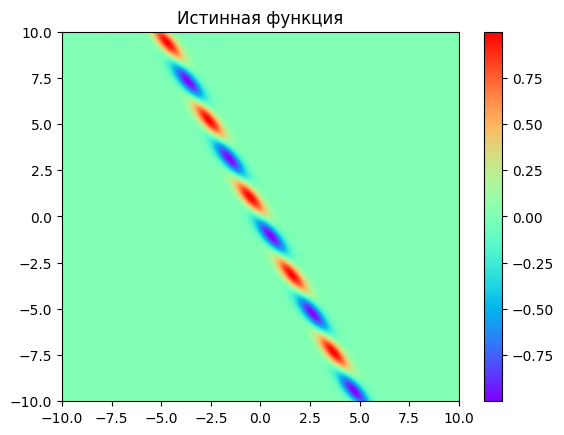

In [4]:
x = np.linspace(-10,10,2000)
y = np.linspace(-10,10,2000)
x,y = np.meshgrid(x, y)
fig, ax = plt.subplots()
z_fun = foo(x,y)
z_min, z_max = -np.abs(z_fun).max(), np.abs(z_fun).max()
c = ax.pcolormesh(x, y, z_fun, cmap='rainbow', vmin=z_min, vmax=z_max)
ax.set_title('Истинная функция')
ax.axis([x.min(), x.max(), y.min(), y.max()])
fig.colorbar(c, ax=ax)

plt.show()

В качестве обучающей выборки необходимо сгенерировать 20000 точек случайным образом.

In [5]:
points = torch.rand(20000,2)*20 - 10
points.to(device)

tensor([[ 9.3260,  7.0471],
        [-9.5263, -4.2013],
        [ 4.0730,  1.5024],
        ...,
        [-8.5923,  7.6212],
        [-2.9336,  6.6543],
        [ 5.7927, -1.1434]], device='cuda:0')

In [6]:
device

device(type='cuda')

In [7]:
z = foo(points[:,0], points[:,1]).reshape(-1,1)
z.to(device)

C:\Users\Petr\AppData\Local\Temp\ipykernel_38440\3007181986.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return np.sin(x + 2*y)*np.exp(-(2*x + y)**2)


tensor([[-0.0000e+00],
        [ 0.0000e+00],
        [ 2.6599e-41],
        ...,
        [ 6.8402e-41],
        [-4.3784e-01],
        [-0.0000e+00]], device='cuda:0')

In [8]:
class NeuralNetwork(nn.Module):
    def __init__(self, hidden_size=64, dropout=False):
        super().__init__()
        self.linear1 = nn.Linear(2, hidden_size)
        self.linear2 = nn.Linear(hidden_size, hidden_size)
        self.linear3 = nn.Linear(hidden_size, hidden_size)
        self.linear4 = nn.Linear(hidden_size, 1)
        if dropout:
            self.dropout = nn.Dropout(0.2)
        else:
            self.dropout = lambda x: x

    def forward(self, x):
        x = self.linear1(x)
        x = nn.functional.leaky_relu(x)
        x = self.linear2(x)
        x = nn.functional.leaky_relu(x)
        x = self.linear3(x)
        x = nn.functional.leaky_relu(x)
        x = self.dropout(x)
        x = self.linear4(x)
        return x


In [9]:
model = NeuralNetwork(hidden_size=128, dropout=False)

In [10]:
from torchsummary import summary

model = model.to(device)
summary(model, (1, 2))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1               [-1, 1, 128]             384
            Linear-2               [-1, 1, 128]          16,512
            Linear-3               [-1, 1, 128]          16,512
            Linear-4                 [-1, 1, 1]             129
Total params: 33,537
Trainable params: 33,537
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.13
Estimated Total Size (MB): 0.13
----------------------------------------------------------------


Разделить получившийся датасет на train / test / val в отношениях 70% / 15% / 15%, соответственно.

In [11]:
x_train, x_test, y_train, y_test = train_test_split(points, z, train_size=0.7)
x_test, x_val, y_test, y_val = train_test_split(points, z, train_size=0.5)

In [12]:
x_train = x_train.to(device)
y_train = y_train.to(device)

x_test = x_test.to(device)
y_test = y_test.to(device)

x_val = x_val.to(device)
y_val = y_val.to(device)

In [13]:
criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

In [14]:
def train_model(model, num_epochs, criterion, optimizer):
    train_history = []
    val_history = []
    for epoch in range(num_epochs):

        pred_y = model(x_train)
        train_loss = criterion(pred_y, y_train)

        pred_y_val = model(x_val)
        val_loss = criterion(pred_y_val, y_val)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()
        print('epoch {}, train_loss {}, val_loss {}'.format(epoch, train_loss.item(), val_loss.item()))
        train_history.append(train_loss.cpu().detach().numpy())
        val_history.append(val_loss.cpu().detach().numpy())
        
    return train_history, val_history
    

epoch 0, train_loss 0.06137678772211075, val_loss 0.062269724905490875
epoch 1, train_loss 0.09314975887537003, val_loss 0.09328799694776535
epoch 2, train_loss 0.04698272794485092, val_loss 0.04683623090386391
epoch 3, train_loss 0.019543590024113655, val_loss 0.01975611224770546
epoch 4, train_loss 0.0379040353000164, val_loss 0.03858241066336632
epoch 5, train_loss 0.04666941240429878, val_loss 0.047461509704589844
epoch 6, train_loss 0.0344906747341156, val_loss 0.035126879811286926
epoch 7, train_loss 0.02084958739578724, val_loss 0.021261030808091164
epoch 8, train_loss 0.017915211617946625, val_loss 0.01815149374306202
epoch 9, train_loss 0.023085854947566986, val_loss 0.023233693093061447
epoch 10, train_loss 0.02750377729535103, val_loss 0.027635646983981133
epoch 11, train_loss 0.02665262669324875, val_loss 0.026814239099621773
epoch 12, train_loss 0.02252523973584175, val_loss 0.022725539281964302
epoch 13, train_loss 0.01919385977089405, val_loss 0.019430074840784073
epoch 

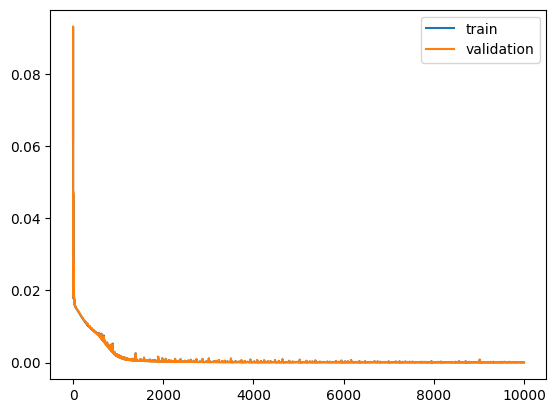

In [15]:
train_history, val_history = train_model(model=model,num_epochs=10000, criterion=criterion, optimizer=optimizer)
plt.plot(train_history, label='train')
plt.plot(val_history, label='validation')
plt.legend()   
plt.show()

In [16]:
x = np.linspace(-10,10,2000)
y = np.linspace(-10,10,2000)
x_model = np.array(np.meshgrid(x, y))
x_model = torch.FloatTensor(x_model)
x_model = x_model.reshape(2,-1).T
x_model = x_model.to(device)
z_model = model(x_model)
z_model = z_model.view(2000,-1)
z_model = z_model.cpu().detach().numpy()

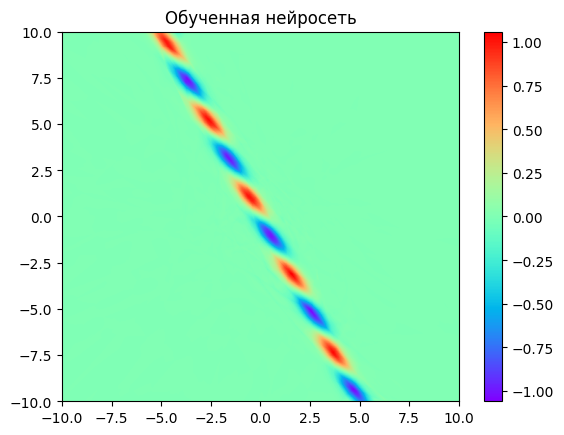

In [17]:
x,y = np.meshgrid(x, y)
fig, ax = plt.subplots()
z_min, z_max = -np.abs(z_model).max(), np.abs(z_model).max()
c = ax.pcolormesh(x, y, z_model, cmap='rainbow', vmin=z_min, vmax=z_max)
ax.set_title('Обученная нейросеть')
ax.axis([x.min(), x.max(), y.min(), y.max()])
fig.colorbar(c, ax=ax)
plt.show()

#### Результаты:


a) Посчитать метрику Mean Square Error(MSE) на test.

In [18]:
mse_test = criterion(model(x_test), y_test)
print(f"MSE на тестовых данных: {mse_test.item():.6f}, RMSE: {mse_test.sqrt().item():.6f}")

MSE на тестовых данных: 0.000031, RMSE: 0.005604


b) Нарисовать график, в котором сравнивается истинная функция и ее аппроксимированный вариант (предсказываемый моделью).

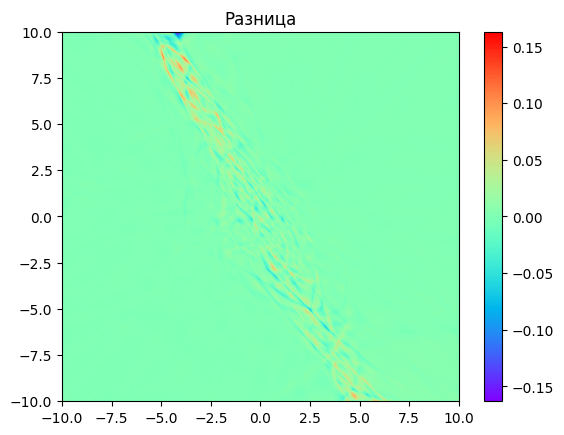

In [19]:
diff = z_model - z_fun
fig, ax = plt.subplots()
z_min, z_max = -np.abs(diff).max(), np.abs(diff).max()
c = ax.pcolormesh(x, y, diff, cmap='rainbow', vmin=z_min, vmax=z_max)
ax.set_title('Разница')
ax.axis([x.min(), x.max(), y.min(), y.max()])
fig.colorbar(c, ax=ax)
plt.show()